In [1]:
# Import NumPy
import numpy as np

# Import Pandas
import pandas as pd

# Import visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Import dataset
from sklearn.datasets import fetch_california_housing

# Import data splitting function
from sklearn.model_selection import train_test_split

# Import preprocessing
from sklearn.preprocessing import StandardScaler

# Import machine learning models
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

# Import pipeline
from sklearn.pipeline import Pipeline

# Import evaluation metrics
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# Import model saving library
import joblib

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load California housing dataset
housing = fetch_california_housing(as_frame=True)

# Convert into DataFrame
df = housing.frame

# Display first five records
print(df.head())

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  


In [3]:
# Display dataset shape
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns)

# Display data types
print("\nData Types:")
print(df.dtypes)

# Display statistical summary
print("\nStatistical Summary:")
print(df.describe())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (20640, 9)

Column Names:
Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'MedHouseVal'],
      dtype='object')

Data Types:
MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object

Statistical Summary:
             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000   
mean       3.870671     28.639486      5.429000      1.096675   1425.476744   
std        1.899822     12.585558      2.474173      0.473911   1132.462122   
min        0.499900      1.000000      0.846154      0.333333      3.000000   
25%        2.563400     18.000000      4.440716      1.006079    787.000000   
50%        3.534800     29.000000      5.229129      1.048780   1166.000000   


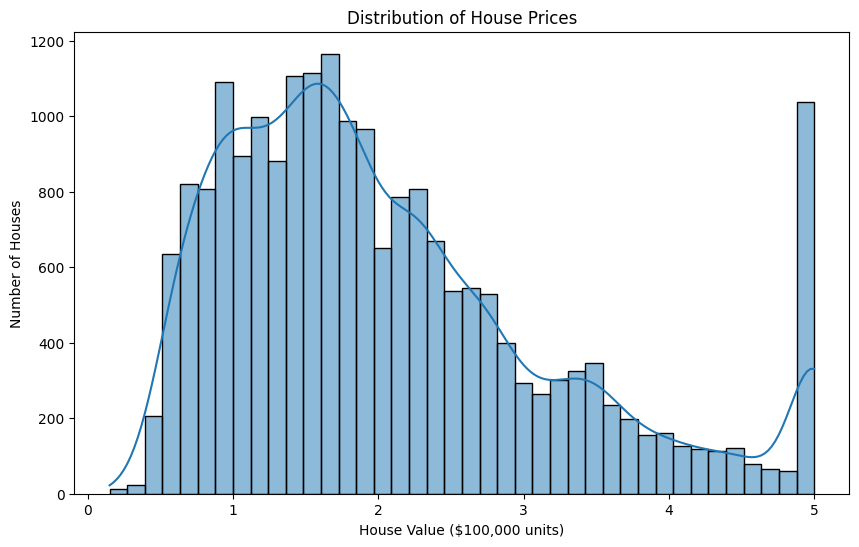

In [4]:
# Set chart size
plt.figure(figsize=(10, 6))

# Create histogram
sns.histplot(df["MedHouseVal"], bins=40, kde=True)

# Add title
plt.title("Distribution of House Prices")

# Add labels
plt.xlabel("House Value ($100,000 units)")
plt.ylabel("Number of Houses")

plt.show()

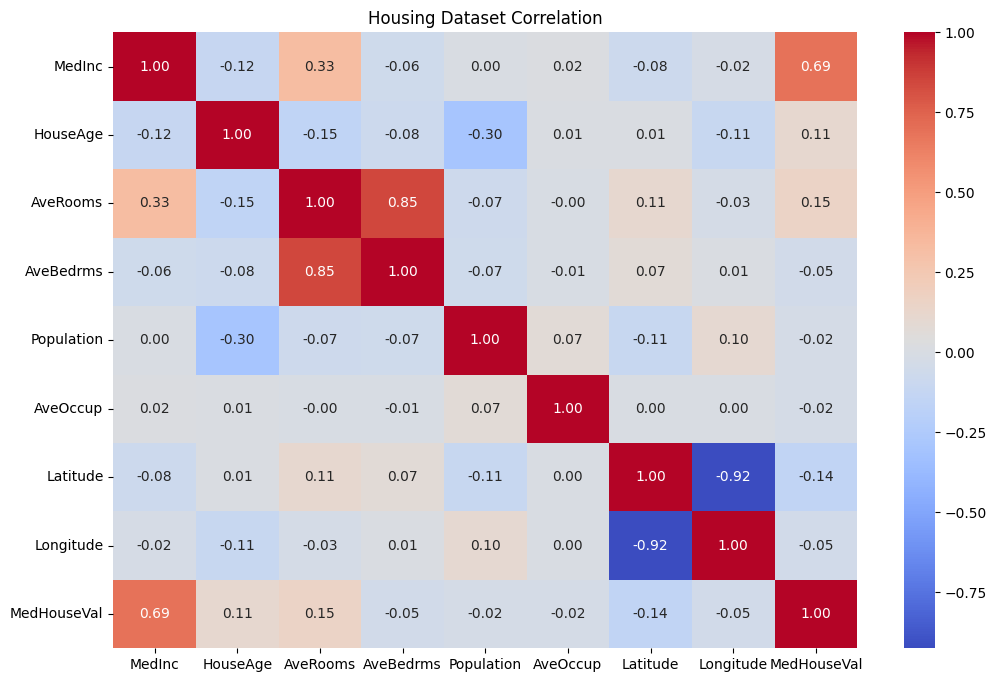

In [5]:
plt.figure(figsize=(12, 8))

correlation = df.corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Housing Dataset Correlation")

plt.show()

In [6]:
# Independent variables (X)
X = df.drop("MedHouseVal", axis=1)

# Dependent variable (y)
y = df["MedHouseVal"]

print("Input Features:")
print(X.head())

print("\nTarget Values:")
print(y.head())

Input Features:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  
0    -122.23  
1    -122.22  
2    -122.24  
3    -122.25  
4    -122.25  

Target Values:
0    4.526
1    3.585
2    3.521
3    3.413
4    3.422
Name: MedHouseVal, dtype: float64


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Records:", X_train.shape[0])

print("Testing Records:", X_test.shape[0])

Training Records: 16512
Testing Records: 4128


In [8]:
# Create Linear Regression pipeline
linear_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

# Create Random Forest model
random_model = Pipeline([
    ("model", RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    ))
])

# Create Gradient Boosting model
gradient_model = Pipeline([
    ("model", GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

# Store all models
models = {
    "Linear Regression": linear_model,
    "Random Forest": random_model,
    "Gradient Boosting": gradient_model
}

print("Three regression models created!")

Three regression models created!


In [9]:
for name, model in models.items():

    # Train the model
    model.fit(X_train, y_train)

    print(name, "training completed!")

Linear Regression training completed!
Random Forest training completed!
Gradient Boosting training completed!


In [10]:
results = []

for name, model in models.items():

    # Predict test data
    predictions = model.predict(X_test)

    # Calculate MAE
    mae = mean_absolute_error(y_test, predictions)

    # Calculate RMSE
    rmse = np.sqrt(
        mean_squared_error(y_test, predictions)
    )

    # Calculate R2 score
    r2 = r2_score(y_test, predictions)

    # Store results
    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

# Convert results into DataFrame
results_df = pd.DataFrame(results)

# Sort models by RMSE
results_df = results_df.sort_values("RMSE")

print(results_df)

               Model       MAE      RMSE  R2 Score
1      Random Forest  0.333221  0.511471  0.800366
2  Gradient Boosting  0.371643  0.542215  0.775645
0  Linear Regression  0.533200  0.745581  0.575788


In [11]:
# Find model with lowest RMSE
best_model_name = results_df.iloc[0]["Model"]

# Select best model
best_model = models[best_model_name]

print("Best Model:", best_model_name)

print("Best RMSE:", results_df.iloc[0]["RMSE"])

print("Best R2 Score:", results_df.iloc[0]["R2 Score"])

Best Model: Random Forest
Best RMSE: 0.5114708009271884
Best R2 Score: 0.8003658517722642


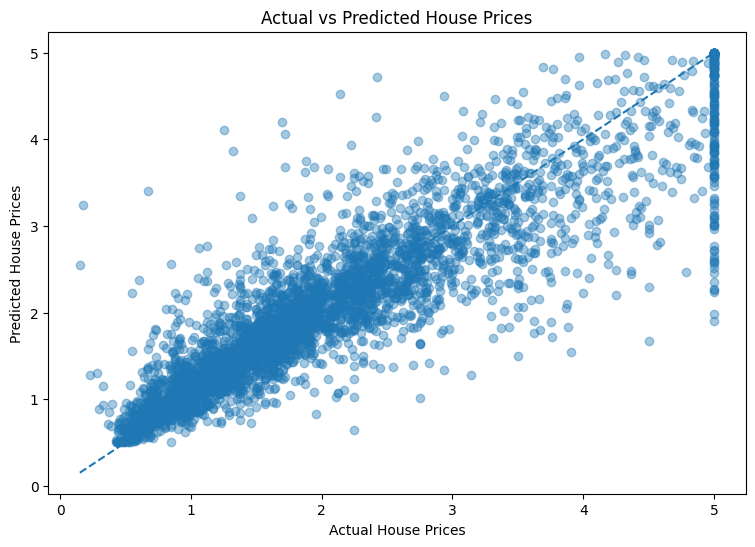

In [12]:
# Predict test dataset
y_pred = best_model.predict(X_test)

# Create comparison chart
plt.figure(figsize=(9, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.4
)

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")

plt.title("Actual vs Predicted House Prices")

plt.show()

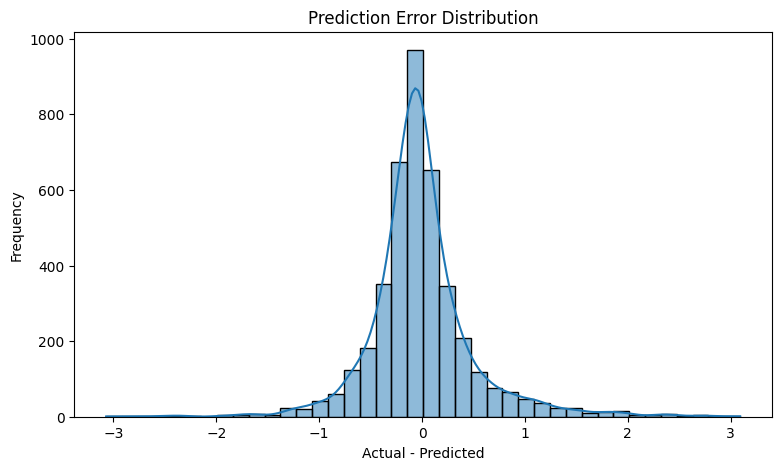

In [13]:
# Calculate prediction errors
errors = y_test - y_pred

plt.figure(figsize=(9, 5))

sns.histplot(errors, bins=40, kde=True)

plt.title("Prediction Error Distribution")

plt.xlabel("Actual - Predicted")

plt.ylabel("Frequency")

plt.show()

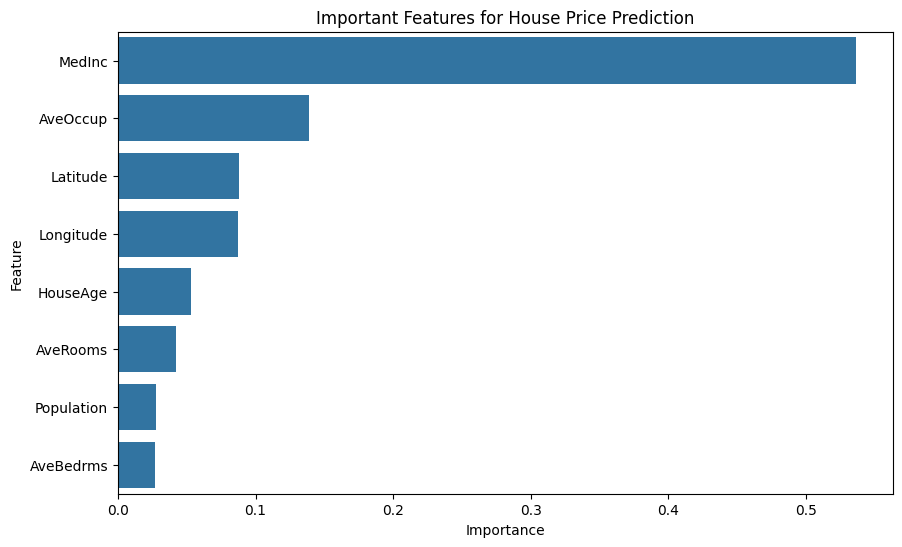

In [14]:
# Access the trained model inside the pipeline
trained_algorithm = best_model.named_steps["model"]

# Check feature importance availability
if hasattr(trained_algorithm, "feature_importances_"):

    importance = trained_algorithm.feature_importances_

else:

    importance = np.abs(
        trained_algorithm.coef_
    )

# Create feature importance DataFrame
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
})

# Sort features
feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

# Plot
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Important Features for House Price Prediction")

plt.show()

In [15]:
# Create a new house record
new_house = pd.DataFrame({
    "MedInc": [5.0],
    "HouseAge": [20],
    "AveRooms": [6.0],
    "AveBedrms": [1.2],
    "Population": [1000],
    "AveOccup": [3.0],
    "Latitude": [34.0],
    "Longitude": [-118.0]
})

# Predict house price
predicted_price = best_model.predict(new_house)[0]

# Convert target units to dollars
predicted_price_dollars = predicted_price * 100000

print("Predicted House Price:")

print(f"${predicted_price_dollars:,.2f}")

Predicted House Price:
$232,443.54


In [16]:
# Save trained model and feature information
joblib.dump(
    {
        "model": best_model,
        "features": list(X.columns),
        "target_multiplier": 100000
    },
    "house_price_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [18]:
!pip install -q gradio

In [19]:
import gradio as gr

print("Gradio installed successfully!")

Gradio installed successfully!


In [21]:
def predict_house_price(
    medinc,
    houseage,
    averooms,
    avebedrms,
    population,
    aveoccup,
    latitude,
    longitude
):

    # Create input DataFrame
    input_data = pd.DataFrame([{
        "MedInc": medinc,
        "HouseAge": houseage,
        "AveRooms": averooms,
        "AveBedrms": avebedrms,
        "Population": population,
        "AveOccup": aveoccup,
        "Latitude": latitude,
        "Longitude": longitude
    }])

    # Generate prediction
    prediction = best_model.predict(input_data)[0]

    # Convert into dollars
    price = prediction * 100000

    # Return result
    return f"Estimated House Value: ${price:,.2f}"

In [22]:
# Create Gradio interface
demo = gr.Interface(

    fn=predict_house_price,

    inputs=[

        gr.Number(label="Median Income", value=5.0),

        gr.Number(label="House Age", value=20),

        gr.Number(label="Average Rooms", value=6.0),

        gr.Number(label="Average Bedrooms", value=1.2),

        gr.Number(label="Population", value=1000),

        gr.Number(label="Average Occupancy", value=3.0),

        gr.Number(label="Latitude", value=34.0),

        gr.Number(label="Longitude", value=-118.0)

    ],

    outputs=gr.Textbox(
        label="Predicted House Value"
    ),

    title="AI House Price Prediction System",

    description="Enter house information to predict its estimated value using Machine Learning."

)

# Launch application
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://76baf757e19b34d5b7.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
